In [1]:
from collections.abc import Callable
from enum import Enum, auto, StrEnum
from pathlib import Path
# import traceback
from PIL import Image
import math
import warnings


import torch
from torch import Tensor
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split

from torchvision import datasets, transforms
from torchvision.utils import make_grid

import matplotlib.pyplot as plt

from tqdm import tqdm

In [2]:
class SinusoidalEmbedding(nn.Module):

    def __init__(self, dim: int, max_period = 10000):
        assert dim % 2 == 0, "dim must be divisible by 2"
        super().__init__()
        half = dim // 2
        freqs = torch.exp(-math.log(max_period) * torch.arange(half, dtype=torch.float32) / half)
        self.register_buffer('freqs', freqs, persistent=False)


    def forward(self, t: Tensor):
        t = t.reshape(-1).float()
        args = t[:, None] * self.freqs[None, :]
        return torch.concat([torch.sin(args), torch.cos(args)], dim=1)
    

def group_norm(channels: int, max_groups: int = 32):
    groups = max_groups
    while (channels % groups) != 0:
        groups //= 2
    return nn.GroupNorm(groups, channels)



class TimeEmbedding(nn.Module):

    def __init__(self,
                 base_dim: int,
                 emb_dim: int,
                 dropout: float = 0.1):
        
        super().__init__()
        self.sinusoid = SinusoidalEmbedding(dim=base_dim)
        self.mlp = nn.Sequential(
            nn.Linear(base_dim, emb_dim),
            nn.SiLU(),
            nn.Linear(emb_dim, emb_dim)
        )


    def forward(self, t: Tensor):

        return self.mlp(self.sinusoid(t))



class ResBlock(nn.Module):

    def __init__(self,
                 in_channel: int,
                 out_channel: int,
                 emb_dim: int,
                 dropout: float):
        super().__init__()

        self.norm1 = group_norm(in_channel)

        self.conv1 = nn.Conv2d(
            in_channels=in_channel,
            out_channels=out_channel,
            kernel_size=3,
            padding=1)

        self.time_proj = nn.Linear(emb_dim, out_channel)

        self.norm2 = group_norm(out_channel)

        self.dropout = nn.Dropout(dropout)
        
        self.conv2 = nn.Conv2d(
            in_channels=out_channel,
            out_channels=out_channel,
            kernel_size=3,
            padding=1)

        nn.init.zeros_(self.conv2.weight)
        nn.init.zeros_(self.conv2.bias)

        self.skip = (
            nn.Conv2d(
                in_channel, 
                out_channel, 
                kernel_size=1)
            
            if in_channel != out_channel 
            else 
            nn.Identity())




    def forward(self, x: Tensor, emb: Tensor):

        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_proj(F.silu(emb))[:, :, None, None]
        h = self.conv2(self.dropout(F.silu(self.norm2(h))))
        return h + self.skip(x)




In [3]:
class UNet(nn.Module):

    def __init__(self, temb_dim: int = 512, dropout: float = 0.1):
        super().__init__()

        self.time_embed = TimeEmbedding(
            base_dim=128,
            emb_dim=temb_dim,
            dropout=dropout
        )

        rb = lambda input, output: ResBlock(
            in_channel=input,
            out_channel=output,
            emb_dim=temb_dim,
            dropout=dropout
        )


        # Encoder

        self.in_conv = nn.Conv2d(
            in_channels=3,
            out_channels=24,
            kernel_size=7,
            padding=3
        )


        self.enc01 = rb(24, 64)
        self.enc02 = rb(64, 128)

        # Downsampling

        self.downsamp01 = nn.Conv2d(
            in_channels=128, 
            out_channels=192, 
            kernel_size=3,
            stride=2,
            padding=1
        )

        self.enc03 = rb(192, 192)

        self.downsamp02 = nn.Conv2d(
            in_channels=192,
            out_channels=256,
            kernel_size=3,
            stride=2,
            padding=1
        )

        self.enc04 = rb(256, 256)

        self.downsamp03 = nn.Conv2d(
            in_channels=256,
            out_channels=384,
            kernel_size=3,
            stride=2,
            padding=1
        )

        self.enc05 = rb(384, 384)

        self.downsamp04 = nn.Conv2d(
            in_channels=384,
            out_channels=512,
            kernel_size=3,
            stride=2,
            padding=1
        )

        self.enc06 = rb(512, 512)


        # Bottleneck

        self.latent1 = rb(512, 512)
        self.latent2 = rb(512, 512)


        # Decoder

        self.upsamp01 = nn.ConvTranspose2d(
            in_channels=512, 
            out_channels=384,
            kernel_size=3,
            stride=2,
            padding=1,
            output_padding=1)

        self.dec01 = rb(384 + 384, 384)

        self.upsamp02 = nn.ConvTranspose2d(
            in_channels=384,
            out_channels=256,
            kernel_size=3,
            stride=2,
            padding=1,
            output_padding=1
        )

        self.dec02 = rb(256 + 256, 256)

        self.upsamp03 = nn.ConvTranspose2d(
            in_channels=256,
            out_channels=192,
            kernel_size=3,
            stride=2,
            padding=1,
            output_padding=1
        )

        self.dec03 = rb(192 + 192, 192)

        self.upsamp04 = nn.ConvTranspose2d(
            in_channels=192,
            out_channels=128,
            kernel_size=3,
            stride=2,
            padding=1,
            output_padding=1
        )

        self.dec04 = rb(128 + 128, 128)

        # Decoder

        self.dec05 = rb(128, 64)

        self.dec06 = rb(64, 24)

        self.out_norm = group_norm(24)

        self.out_conv = nn.Conv2d(
            in_channels=24,
            out_channels=3,
            kernel_size=3,
            stride=1,
            padding=1
        )

        nn.init.zeros_(self.out_conv.weight)
        nn.init.zeros_(self.out_conv.bias)

        return


    def forward(self, x: Tensor, t: Tensor):

        temb = self.time_embed(t)

        h = self.in_conv(x)             # 24 @ H
        h = self.enc01(h, temb)         # 64 @ H
        s1 = self.enc02(h, temb)        # 128 @ H

        s2 = self.enc03(self.downsamp01(s1), temb)          # 192 @ H/2
        s3 = self.enc04(self.downsamp02(s2), temb)          # 256 @ H/4
        s4 = self.enc05(self.downsamp03(s3), temb)          # 384 @ H/8
        h = self.enc06(self.downsamp04(s4), temb)           # 512 @ H/16

        h = self.latent1(h, temb)
        h = self.latent2(h, temb)

        h = self.dec01(                                     # 384 @ H/8
            torch.concat([self.upsamp01(h), s4], dim=1),
            temb
        )

        h = self.dec02(                                     # 256 @ H/4
            torch.concat([self.upsamp02(h), s3], dim=1),
            temb
        )

        h = self.dec03(                                     # 192 @ H/2
            torch.concat([self.upsamp03(h), s2], dim=1),
            temb 
        )


        h = self.dec04(                                     # 128 @ H
            torch.concat([self.upsamp04(h), s1], dim=1),
            temb 
        )


        h = self.dec05(h, temb)                             # 64 @ H

        h = self.dec06(h, temb)                             # 24 @ H


        return self.out_conv(F.silu(self.out_norm(h)))      # 3 @ H








Datasets Section

In [4]:

class RESCLabel(StrEnum):
    NORMAL = 'NORMAL'
    DME = 'DME'
    AMD ='AMD'
    CNV = 'CNV'
    MH = 'MH'
    DRUSEN = 'DRUSEN'
    ALL = '*'

class SplitLabel(StrEnum):
    TEST = 'test'
    TRAIN = 'train'
    VAL = 'val'

class RESCDataset(Dataset):

    def __init__(self, 
                 root_dir: str | Path = 'datasets/retinal-oct', 
                 split:  SplitLabel= SplitLabel.TRAIN,
                 label: RESCLabel = RESCLabel.NORMAL, 
                 transform: Callable | None = None):

        label = '*' if label is None else label
        root_path = Path(root_dir)
        if root_path.is_dir():
            root_path = root_path / split
        if root_path.is_dir():
            self.paths = sorted(root_path.glob(f'{label}/*.jpg'))
            if not self.paths:
                raise FileNotFoundError(f'No dataset found in the directory {root_path.resolve() / label}')
        else:
            raise FileNotFoundError(f'{root_path.resolve()} not a directory') 
        classes = sorted({p.parent for p in self.paths})
        self.class_index = {v: i for i, v in enumerate(classes)}
        self.split = split
        self.transform = transform or transforms.Compose([
            transforms.Resize((128, 128)),
            transforms.ToTensor(),
            transforms.Normalize([0.5] * 3, [0.5] * 3)
        ])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index: int):
        p = self.paths[index]
        image = Image.open(p).convert('RGB')
        return self.transform(image), self.class_index[p.parent]

In [5]:
class XRayLabel(StrEnum):
    NORMAL = 'NORMAL'
    PNEUMONIA = 'PNEUMONIA'

class ChestXRay(Dataset):

    def __init__(self,
                 root_dir: str | Path = 'datasets/chest_xray',
                 split: SplitLabel = SplitLabel.TRAIN,
                 label: XRayLabel = XRayLabel.NORMAL,
                 transform: Callable | None = None):
        super().__init__()
        root_path = Path(root_dir)
        if root_path.is_dir():
            root_path = root_path / split
        if root_path.is_dir():
            self.paths = sorted(root_path.glob(f'{label}/*.jpeg'))
            if not self.paths:
                raise FileNotFoundError(f'No dataset found in the directory {root_path.resolve() / label}')
        else:
            raise FileNotFoundError(f'{root_path.resolve()} is not a directory')
        classes = sorted((p.parent for p in self.paths))
        self.class_index = {v: i for i, v in enumerate(classes)}
        self.transform = transform or transforms.Compose([
            transforms.Resize((128, 128)),
            transforms.ToTensor(),
            transforms.Normalize([0.5] * 3, [0.5] * 3)
        ])

    def __len__(self):
        return len(self.paths)


    def __getitem__(self, index: int):
        p = self.paths[index]
        img = Image.open(p).convert('RGB')
        return self.transform(img), self.class_index[p.parent]

In [6]:
dat = RESCDataset(split='train', label=RESCLabel.NORMAL)
len(dat)

2300

In [7]:
xdat = ChestXRay()
print(len(xdat))


1238


In [8]:
def train(
        loader: DataLoader,
        epochs: int,
        beta_min: float,
        beta_max: float,
        checkpoint_dir: str,
        T: int = 1000,
        lr: float = 2e-4,
        device: str ='cuda',
        verbose: bool = True
):
    
    assert 0 <= beta_min < beta_max < 1,'beta_min must be less than beta_max, and their range is [0, 1)'
    # assert 0 <= noise <= 1, 'the value of noise has a range of [0, 1]' 

    if device == 'cuda' and  torch.cuda.is_available() == False:
        warnings.warn('GPU is notavailable, use device="cpu"', RuntimeWarning)

    betas = torch.linspace(
        beta_min,
        beta_max,
        T,
        device=device
    )

    alpha_bar = torch.cumprod(1-betas, dim=0)

    model = UNet()
    model.to(device)

    checkpoint = Path(checkpoint_dir)

    if checkpoint.exists():

        try:
            state_dict = torch.load(
                f=checkpoint,
                map_location=device,
                weights_only=True
            )

            model.load_state_dict(state_dict=state_dict)

            print(f'The checkpoint named {checkpoint_dir} as been loaded')

        except RuntimeError as e:

            e.add_note(f'[Checkpoint failure] while loading {checkpoint}')
            raise

        except Exception as e:
            exc = type(e)
            raise exc('[Checkpoint failure] ' % e) from e

    else:
        if verbose:
            print(f'No checkpoint named {checkpoint_dir} was found')
            print(f'A new checkpoint will be created')

    optimizer = optim.Adam(
        params=model.parameters(),
        lr=lr
    )

    scaler = torch.amp.GradScaler('cuda')

    model.train()

    loader_size = len(loader)

    for epoch in tqdm(range(epochs), desc=f'Training {epochs} epochs'):

        running_loss = 0.0

        for x0, _ in loader:

            x0 = x0.to(device)
            # batch of current dataset
            batch = x0.shape[0]
            # random timestep
            ts = torch.randint(
                low=0,
                high=T,
                size=(batch,),
                device=device
            )
            # shape -> [b]
            alpha_bar_t: Tensor = alpha_bar[ts]
            # shape -> [b, 1, 1, 1]
            alpha_bar_t = alpha_bar_t[:, None, None, None]
            # noise
            epsilon: Tensor = torch.randn_like(x0)
            # noisy data
            xt: Tensor = (alpha_bar_t.sqrt() * x0) + ((1 - alpha_bar_t).sqrt() * epsilon)

            with torch.autocast('cuda', dtype=torch.float16):
                # predicted noise
                epsilon_pred = model(xt, ts)

            loss = F.mse_loss(epsilon_pred, epsilon)

            optimizer.zero_grad()                   # clears old grads
            scaler.scale(loss).backward()           # computes new grads
            scaler.unscale_(optimizer=optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer=optimizer)        # update weights
            scaler.update()                         # adjusts the scale
        
            # loss.backward()
            # nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            # optimizer.step()

            running_loss += loss.item()

        average_loss = running_loss / loader_size

        print(
            f'Epoch {epoch + 1}, / {epochs}',
            f'Loss: {average_loss:.6f}'
        )

        torch.save(model.state_dict(), checkpoint)

    return model





    
    



In [ ]:
data = RESCDataset(split='train', label=RESCLabel.NORMAL)
dataloader = DataLoader(
    dataset=data,
    batch_size=8,
    shuffle=True,
    num_workers=2,
    drop_last=False,
    multiprocessing_context='fork'
)

beta_min=1e-4
beta_max=0.02
T=10000,

# model = train(loader=dataloader, epochs=20, beta_min=beta_min, beta_max=beta_max, checkpoint_dir='checkpoints/resc.pth')

In [21]:
data02 = ChestXRay()

dataloader = DataLoader(
    dataset=data02,
    batch_size=8,
    shuffle=True,
    num_workers=2,
    drop_last=False,
    multiprocessing_context='fork'
)

model = train(loader=dataloader, epochs=5, beta_min=beta_min, beta_max=beta_max, checkpoint_dir='checkpoints/xray.pth')

The checkpoint named checkpoints/xray.pth as been loaded


Training 5 epochs:  20%|██        | 1/5 [00:45<03:01, 45.29s/it]

Epoch 1, / 5 Loss: 0.008440


Training 5 epochs:  40%|████      | 2/5 [01:31<02:16, 45.55s/it]

Epoch 2, / 5 Loss: 0.010570


...

Epoch 3, / 5 Loss: 0.008740


Training 5 epochs:  80%|████████  | 4/5 [03:03<00:45, 45.89s/it]

Epoch 4, / 5 Loss: 0.010325


Training 5 epochs: 100%|██████████| 5/5 [03:49<00:00, 45.86s/it]

Epoch 5, / 5 Loss: 0.008898


The contional mean, expectation or the center of the probability distribution
$$\mathbb{E}[x_{t-1} \mid x_t] = \int x_{t-1}\, p(x_{t-1} \mid x_t)\, dx_{t-1}$$
mean → $\mu_\theta(x_t, t)$
$$\mu_\theta(x_t, t) = \frac{1}{\sqrt{\alpha_t}} \left( x_t - \frac{\beta_t}{\sqrt{1 - \bar\alpha_t}}\, \epsilon_\theta(x_t, t) \right)$$

In [11]:
# sample

@torch.no_grad()
def sample(
    model: nn.Module,
    batch: int = 8,
    T: int = 1000,
    beta_min: float = 1e-4,
    beta_max: float = 0.02,
    size: tuple[int, int] = (128, 128),
    device: str = 'cuda'
):
    model.eval()            # disable droput

    betas = torch.linspace(
        start=beta_min,
        end=beta_max,
        steps=T,
        device=device
    )

    alphas = 1 - betas
    alpha_bar = torch.cumprod(input=alphas, dim=0)   

    x0 = torch.randn(batch, 3, *size, device=device)     # pure noise

    for t in tqdm(reversed(range(T)), desc='sampling', total=T):

        ts = torch.full((batch,), t, device=device, dtype=torch.long)

        with torch.autocast(device_type=device, dtype=torch.float16):
            epsilon = model(x0, ts)

        epsilon = epsilon.float()

        mean = (x0 - betas[t]/(1 - alpha_bar[t]).sqrt() * epsilon) / alphas[t].sqrt()

        if t > 0:
            x0 = mean + betas[t].sqrt() * torch.randn_like(x0)
        else:
            x0 = mean

    model.train()

    return (x0.clamp(-1, 1) + 1) / 2

        

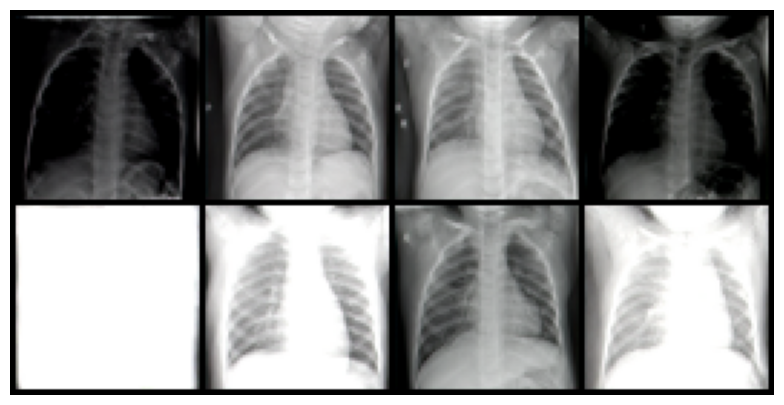

In [24]:
torch.manual_seed(0)

# img = sample(model, batch=8)

# grid = make_grid(img, nrow=4, padding=2)

plt.figure(figsize=(10, 5))

small = F.interpolate(img, size=(64, 64), mode='area')   # [B, 3, 64, 64]
plt.imshow(make_grid(small, nrow=4).permute(1, 2, 0).cpu())

# plt.imshow(grid.permute(1, 2, 0).cpu( ))

plt.axis('off')

plt.show()





In [13]:
@torch.inference_mode()
def test(
    loader: Dataset,
    beta_min: float,
    beta_max: float,
    T: int,
    checkpoint_dir: str,
    device: str='cuda'
):
    assert torch.cuda.is_available(), 'GPU not available, use device="cpu"'
    assert 0 <= beta_min < beta_max < 1,'beta_min must be less than beta_max, and their range is [0, 1)'
    assert 0 <= noise <= 1, 'the value of noise has a range of [0, 1]'  

    betas = torch.linspace(
        start=beta_min,
        end=beta_max,
        steps=T,
        device=device
    )

    alpha_bar = torch.cumprod(1-betas, dim=0)

    




$\boxed{O=\left\lfloor\frac{I+2P-K}{S}\right\rfloor+1}$


- \(I\): input size (height or width)
- \(O\): output size
- \(P\): padding on each side
- \(K\): kernel size
- \(S\): stride

In [14]:
    # padding
    # valid = 0
    # same = 1

def conv_size(input: int, k:int, pad: int = 0, s:int=1):
    """
    input = in-channel
    k = kernel
    s = stride
    pad = padding
    """
    assert  k % 2, 'an odd number is preferred'

    return ((input + (2 * pad) - k) // s) + 1


def transpose_size(input, k, pad, s = 1, out=0, d=1):
    """
    input = in-channel
    k = kernel
    s = strise
    pad = padding
    oot = out-padding
    d =dilation
    """
    assert  k % 2, 'an odd number is preferred'

    return (input - 1) * s - (2 * pad) - (d * (k - 1)) + out + 1

In [15]:
conv_size(input=1024, k=3 ,pad=1, s=2)


512

In [16]:
384 *2

768